In [2]:
import polars as pl 
import geopandas as gpd
import polars as pl 
import duckdb
import os 
import polars as pl 
from cpom.masks.masks import Mask

os.environ['CPOM_SOFTWARE_DIR'] = "/home/willisc3/cpom_software2"
# from cpom.areas.area_plot import Polarplot
from cpom.altimetry.datasets.parquet_tools.spatio_temporal import (parquet_filter,
                                                    #polygon_from_mask, 
                                                    get_db_connection, 
                                                    reproject, 
                                                    to_geometry
                                                    )

con = get_db_connection()
##gdf = polygon_from_mask("greenland_icesheet_2km_grid_mask_mouginot2019",
##                            basin_numbers=["NW"], target_crs=3413)

In [3]:
old_grid = pl.read_parquet("/home/willisc3/luna/CPOM/willisc3/SEC/greenland_cs2_5km/gridded_altimetry/**/*.parquet")

In [6]:
new_ds_path = "/home/willisc3/luna/CPOM/archive/SATS/_PARQUET_STORE/north/cs2/CryoTEMPO_baseline_D/**/*.parquet"
new_ds = pl.read_parquet(new_ds_path)
parquet_filter(new_ds_path, data_crs = 3413,  engine="polars").get_cpom_grid_mask(mask = Mask(
        "greenland_icesheet_2km_grid_mask"
    )
).run(materialize=True)

latitude,longitude,elevation,elevation_err,power,mode,x,y,source,idx,ascending,datetime,year,month,day,h3_cell_id
f64,f64,f32,f32,f32,i8,f64,f64,str,i32,bool,datetime[μs],i64,i8,i8,u64
67.625555,310.931577,1220.3396,0.567039,2.465873,3,-174091.344966,-2.4476e6,"""CS_OFFL_SIR_TDP_LI_GREENL_2010…",1396,false,2010-12-28 08:31:59.823540,2010,12,28,608108214982017023
67.628362,310.929464,1219.393433,0.560514,3.239487,3,-174159.184339,-2.4473e6,"""CS_OFFL_SIR_TDP_LI_GREENL_2010…",1395,false,2010-12-28 08:31:59.779167,2010,12,28,608108214982017023
67.610465,312.062494,1573.894775,0.383496,4.292696,1,-125835.93733,-2.4523e6,"""CS_OFFL_SIR_TDP_LI_GREENL_2010…",4241,false,2010-11-27 09:59:37.530421,2010,11,27,608108250415497215
67.610852,312.064077,1604.320312,0.382189,-0.549093,1,-125765.931269,-2.4522e6,"""CS_OFFL_SIR_TDP_LI_GREENL_2010…",4239,false,2010-11-27 09:59:37.436079,2010,11,27,608108250415497215
67.610488,312.063659,1601.889771,0.382669,6.194547,1,-125785.931269,-2.4523e6,"""CS_OFFL_SIR_TDP_LI_GREENL_2010…",4240,false,2010-11-27 09:59:37.483250,2010,11,27,608108250415497215
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
81.80677,313.452408,22.554365,NaN,11.060922,3,-24009.624907,-888680.731078,"""CS_OFFL_SIR_TDP_LI_GREENL_2025…",748,true,2025-02-06 03:33:57.162360,2025,2,6,608045355350622207
81.804237,313.460264,22.664974,0.134142,9.784307,3,-23895.180775,-888959.736699,"""CS_OFFL_SIR_TDP_LI_GREENL_2025…",747,true,2025-02-06 03:33:57.117062,2025,2,6,608045355350622207
81.798473,313.530676,22.843334,0.133393,7.001218,3,-22818.792263,-889615.693045,"""CS_OFFL_SIR_TDP_LI_GREENL_2025…",838,false,2025-02-22 16:37:04.350118,2025,2,22,608045355367399423


In [7]:
this_filter = parquet_filter(new_ds_path, data_crs = 3413).get_cpom_grid_mask(mask = Mask(
        "greenland_icesheet_2km_grid_mask"
    )
).run()

In [11]:
type(this_filter)

polars.dataframe.frame.DataFrame

In [17]:
pl.read_parquet(new_ds_path)

latitude,longitude,elevation,elevation_err,power,mode,x,y,source,idx,ascending,datetime,year,month,day,h3_cell_id
f32,f32,f32,f32,f32,i8,f64,f64,str,i32,bool,datetime[μs],i64,i8,i8,u64
67.63443,306.128143,25.786844,NaN,7.051567,3,-378283.223717,-2.4235e6,"""CS_OFFL_SIR_TDP_LI_GREENL_2010…",2388,false,2010-11-12 11:07:35.133373,2010,11,12,608105797016092671
67.517105,306.08844,25.569555,NaN,6.0803,3,-382005.623444,-2.4362e6,"""CS_OFFL_SIR_TDP_LI_GREENL_2010…",2431,false,2010-11-12 11:07:37.091622,2010,11,12,608105798458933247
67.519836,306.089203,25.527605,NaN,7.134151,3,-381926.217927,-2.4359e6,"""CS_OFFL_SIR_TDP_LI_GREENL_2010…",2430,false,2010-11-12 11:07:37.046082,2010,11,12,608105798458933247
67.63726,306.126801,25.743599,NaN,7.314597,3,-378291.491783,-2.4231e6,"""CS_OFFL_SIR_TDP_LI_GREENL_2010…",2387,false,2010-11-12 11:07:35.087831,2010,11,12,608105797016092671
67.527908,306.094574,25.391306,NaN,8.389582,3,-381557.046801,-2.4351e6,"""CS_OFFL_SIR_TDP_LI_GREENL_2010…",2427,false,2010-11-12 11:07:36.909462,2010,11,12,608105798458933247
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
59.705296,315.74411,43.272133,NaN,9.261815,3,43601.021443,-3.3570e6,"""CS_OFFL_SIR_TDP_LI_GREENL_2025…",45,true,2025-02-01 04:22:10.513632,2025,2,1,608463349386051583
59.70253,315.743713,43.451931,NaN,9.567897,3,43580.937971,-3.3573e6,"""CS_OFFL_SIR_TDP_LI_GREENL_2025…",44,true,2025-02-01 04:22:10.468552,2025,2,1,608463349386051583
59.699692,315.742004,42.71146,NaN,8.843573,3,43485.29883,-3.3577e6,"""CS_OFFL_SIR_TDP_LI_GREENL_2025…",43,true,2025-02-01 04:22:10.423473,2025,2,1,608463349637709823


## Get download 

In [13]:
# import argparse
# import duckdb
# from enum import Enum

# BUFFER_METERS = 0
# H3_RESOLUTION = 7

# class SortMethod(str, Enum):
#     HILBERT = "hilbert"
#     H3      = "h3"
#     GRID    = "grid"


# # # set threads 
# con.execute("SET threads TO 15;")
# # con.execute("SET memory_limit TO '100GB';")
# # print db tables 
# con.execute("SHOW TABLES;").df()

# def convert(
#     parquet_path: str,
#     con: duckdb.DuckDBPyConnection,
#     table_name: str,
#     lat_col: str = "latitude",
#     lon_col: str = "longitude",
#     h3_res: int = H3_RESOLUTION,
#     compression: str = "zstd",
#     compression_level: int = 3,
#     sort_method: SortMethod = SortMethod.HILBERT,
#     grid_resolution_deg: float = 1.0,
# ) -> None:
#     source = f"read_parquet('{parquet_path}', hive_partitioning=true)"

#     if sort_method == SortMethod.HILBERT:
#         table_name = f"{table_name}_hilbert"
#         print("Computing spatial extent for Hilbert curve...")
#         min_lon, min_lat, max_lon, max_lat = con.execute(f"""
#             SELECT MIN({lon_col}), MIN({lat_col}), MAX({lon_col}), MAX({lat_col})
#             FROM {source}
#         """).fetchone()

#         box2d = f"ST_MakeBox2D(ST_Point({min_lon}, {min_lat}), ST_Point({max_lon}, {max_lat}))"
#         order_clause = f"ST_Hilbert({lon_col}, {lat_col}, {box2d})"
#     elif sort_method == SortMethod.H3:
#         table_name = f"{table_name}_h3"
#         order_clause = "h3_cell_id"
#     elif sort_method == SortMethod.GRID:
#         table_name = f"{table_name}_grid"
#         order_clause = f"FLOOR({lat_col} / {grid_resolution_deg})::INT, FLOOR({lon_col} / {grid_resolution_deg})::INT"

#     print(f"Creating table '{table_name}' (sort={sort_method.value}")
#     con.execute(f"""
#     COPY (
#         SELECT * FROM (
#             SELECT
#                 *,
#                 CAST(h3_latlng_to_cell({lat_col}, {lon_col}, {h3_res}) AS UBIGINT) AS h3_cell_id
#             FROM {source}
#         )
#         ORDER BY {order_clause}
#     ) TO '{"/home/willisc3/luna/CPOM/willisc3/new_archive_test/"}'
#     (FORMAT parquet, COMPRESSION '{compression}', COMPRESSION_LEVEL {compression_level});
# """)

#     row_count = con.execute(f"SELECT COUNT(*) FROM {table_name}").fetchone()[0]
#     print(f"Done — {row_count:,} rows written to table '{table_name}'.")

#     con.execute(f"""
#         COMMENT ON TABLE {table_name} IS
#         'sort={sort_method.value} | h3_res={h3_res} | cols={lat_col}/{lon_col}';
#     """)


# def main(argv=None):
#     parser = argparse.ArgumentParser(description="Parquet -> DuckDB with H3 + spatial sort")
#     parser.add_argument(
#         "--parquet_path",
#         default="/home/willisc3/luna/CPOM/willisc3/new_archive_test/north/cs2/CryoTEMPO_baseline_D/**/*.parquet",
#         help="Root directory of partitioned parquet",
#     )
#     parser.add_argument(
#         "--db_path",
#         default="/home/willisc3/luna/CPOM/willisc3/new_archive_test/altimetry_data.duckdb",
#         help="Output .duckdb file path",
#     )
#     parser.add_argument("--table_name", default="CryoTEMPO_baseline_D", help="Target table name")
#     parser.add_argument("--lat_col", default="latitude")
#     parser.add_argument("--lon_col", default="longitude")
#     parser.add_argument("--compression", default="zstd", choices=["zstd", "snappy", "lz4", "uncompressed"])
#     parser.add_argument("--compression_level", type=int, default=3)
#     parser.add_argument("--sort_method", default="hilbert", choices=[m.value for m in SortMethod])
#     parser.add_argument("--grid_resolution_deg", type=float, default=1.0)
#     parser.add_argument("--all_methods", action="store_true", help="Run all 3 sort methods, appending _hilbert/_h3/_grid to table_name")
#     args = parser.parse_args(argv)

#     for method in list(SortMethod):
#         name = f"{args.table_name}_{method.value}" if args.all_methods else args.table_name
#         convert(
#             parquet_path=args.parquet_path,
#             con=con,
#             table_name=name,
#             lat_col=args.lat_col,
#             lon_col=args.lon_col,
#             h3_res=H3_RESOLUTION,
#             compression=args.compression,
#             compression_level=args.compression_level,
#             sort_method=method,
#             grid_resolution_deg=args.grid_resolution_deg,
#         )


# main([])

## Bounding box duckdb 

In [2]:
from memory_profiler import memory_usage

# input = "/home/willisc3/luna/CPOM/willisc3/SEC/gis_is2_5km/gridded_altimetry/**/*.parquet"
input = "/home/willisc3/luna/CPOM/willisc3/new_archive_test/north/cs2/CryoTEMPO_baseline_D/**/*.parquet"

In [12]:

def bbox_query_polars(
    input: str,
    min_lon: float,
    min_lat: float,
    max_lon: float,
    max_lat: float,
    columns: list[str] | None = None,
    lat_col: str = "latitude",
    lon_col: str = "longitude",
    limit: int | None = None,
) -> pl.DataFrame:
    lf = pl.scan_parquet(input)

    lf = lf.filter(
        (pl.col(lon_col) >= min_lon) &
        (pl.col(lon_col) <= max_lon) &
        (pl.col(lat_col) >= min_lat) &
        (pl.col(lat_col) <= max_lat)
    )

    lf = lf.filter(pl.col("year") == 2020)

    if columns:
        lf = lf.select(columns)

    if limit:
        lf = lf.limit(limit)

    return lf.sink_parquet("pl_output.parquet", compression="zstd", compression_level=3)

def profile_bbox():
    return bbox_query_polars(
        input, min_lon=minx, min_lat=miny,
        max_lon=maxx, max_lat=maxy,
        lat_col="y", lon_col="x"
    )

mem, result = memory_usage(profile_bbox, retval=True, interval=0.1, timeout=600)
print(f"Peak memory: {max(mem):.1f} MiB")
print(f"Baseline:    {min(mem):.1f} MiB")
print(f"Delta:       {max(mem) - min(mem):.1f} MiB")

ComputeError: cannot compare string with numeric type (f32)

This error occurred in the following expression:
	[(col("y_min")) > ("maxy")]
while evaluating this larger expression:
	[([([([([(col("year_nc")) == (col("len"))]) | ([([(col("year_min")) > (2020)]) & (col("year_min").alias("").is_not_null())])]) | ([([(col("year_max")) < (2020)]) & (col("year_max").alias("").is_not_null())])]) | ([([(col("y_min").alias("").is_not_null()) & (col("y_min").alias("").is_not_nan())]) & ([(col("y_min")) > ("maxy")])])]) | ([([(col("x_min").alias("").is_not_null()) & (col("x_min").alias("").is_not_nan())]) & ([(col("x_min")) > ("maxx")])])]


In [10]:
pl.read_parquet("pl_output.parquet")

latitude,longitude,elevation,power,mode,source,idx,ascending,x,y,datetime,year,month,day,h3_cell_id
f32,f32,f32,f32,i8,str,i32,bool,f32,f32,datetime[μs],i64,i8,i8,u64
73.299187,303.022034,21.296255,11.865742,3,"""CS_OFFL_SIR_TDP_LI_GREENL_2020…",3072,true,-378037.75,-1.7819e6,2020-06-25 16:22:41.109241,2020,6,25,608102263130423295
73.183006,303.046661,21.636091,23.556845,3,"""CS_OFFL_SIR_TDP_LI_GREENL_2020…",2988,true,-379932.71875,-1.7946e6,2020-04-01 20:35:00.577917,2020,4,1,608102262979428351
73.180206,303.045258,21.457533,31.082296,3,"""CS_OFFL_SIR_TDP_LI_GREENL_2020…",2987,true,-380040.5625,-1.7949e6,2020-04-01 20:35:00.533119,2020,4,1,608102262979428351
73.29644,303.022339,21.409845,11.718378,3,"""CS_OFFL_SIR_TDP_LI_GREENL_2020…",3071,true,-378090.75,-1.7822e6,2020-06-25 16:22:41.063982,2020,6,25,608102263147200511
73.293755,303.024414,21.285044,12.194933,3,"""CS_OFFL_SIR_TDP_LI_GREENL_2020…",3070,true,-378088.28125,-1.7825e6,2020-06-25 16:22:41.018724,2020,6,25,608102263147200511
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
79.230598,305.247833,1850.250854,8.950462,1,"""CS_OFFL_SIR_TDP_LI_GREENL_2020…",152,false,-198170.3125,-1.1530e6,2020-12-07 21:12:11.401454,2020,12,7,608046022026854399
79.230209,305.163696,1847.432373,10.55317,1,"""CS_OFFL_SIR_TDP_LI_GREENL_2020…",1786,true,-199870.421875,-1.1528e6,2020-02-18 22:18:47.981773,2020,2,18,608046021942968319
79.230209,305.163696,1846.824585,6.991413,1,"""CS_OFFL_SIR_TDP_LI_GREENL_2020…",1811,true,-199870.421875,-1.1528e6,2020-08-29 12:46:04.638666,2020,8,29,608046021942968319


## Exact polygon 

In [1]:
con.execute("LOAD spatial;")
columns = None
path = "/home/willisc3/luna/CPOM/willisc3/new_archive_test/north/cs2/CryoTEMPO_baseline_D/**/*.parquet"
h3_col = "h3_cell_id"
lon_col = "x"
lat_col = "y"

NameError: name 'con' is not defined

In [9]:


# H3 cover computed in WGS84 using buffered projected polygon.
polygon, src_crs = to_geometry(gdf)
polygon_4326 = reproject(polygon.buffer(5000), src_crs=src_crs, dst_crs=4326)
cells = h3.geo_to_cells(polygon_4326.__geo_interface__, res=7)
if not cells:
    raise ValueError("H3 cells covering polygon: 0")

cell_list = ", ".join(str(h3.str_to_int(c)) for c in cells)
print(f"H3 cells covering polygon: {len(cells)}")

cols = ", ".join(columns) if columns else "*"
wkt = polygon.wkt.replace("'", "''")
minx, miny, maxx, maxy = polygon.bounds

# Quick diagnostics to see which stage removes rows.
query = f"""
    SELECT {cols}
    FROM read_parquet('{path}', hive_partitioning=true)
    WHERE {h3_col} IN ({cell_list})
    AND   {lon_col} BETWEEN {minx} AND {maxx}
    AND   {lat_col} BETWEEN {miny} AND {maxy}
    AND   ST_Within(
            ST_Point({lon_col}, {lat_col}),
            ST_GeomFromText('{wkt}')
    )
    
"""
# result = con.execute(query).pl()

# con.execute(f"COPY ({query}) TO '{"test.parquet"}' (FORMAT PARQUET)")

# pl.read_parquet("test.parquet")

H3 cells covering polygon: 54772


In [10]:
query

"\n    SELECT *\n    FROM read_parquet('/home/willisc3/luna/CPOM/willisc3/new_archive_test/north/cs2/CryoTEMPO_baseline_D/**/*.parquet', hive_partitioning=true)\n    WHERE h3_cell_id IN (608102516348944383, 608100747225071615, 608101776977035263, 608103611985035263, 608043886371143679, 608102582233071615, 608100588613271551, 608044044982943743, 608101711092908031, 608100681340944383, 608103770596835327, 608102740844871679, 608103968249217023, 608102938497253375, 608103743753289727, 608103480216780799, 608103995092762623, 608043754602889215, 608100390960889855, 608102714001326079, 608100654497398783, 608100720381526015, 608028122868088831, 608100615456817151, 608044889279561727, 608101301141635071, 608043925411725311, 608100561769725951, 608100337273798655, 608103941405671423, 608043700915798015, 608043688718761983, 608102911653707775, 608100627653853183, 608102687157780479, 608100403157925887, 608102753041907711, 608101723289944063, 608102528545980415, 608103638828580863, 6081003104302

In [ ]:
H3_RESOLUTION  = 7
COVERING_RES   = 7
BUFFER_METERS  = 10000

polygon, src_crs = to_geometry(gdf)
polygon_4326 = reproject(polygon, src_crs=src_crs, dst_crs=4326)

t0 = time.perf_counter()
covering = h3.h3shape_to_cells(
    h3.geo_to_h3shape(polygon_4326.__geo_interface__),
    COVERING_RES,
 )
covering_ints = [h3.str_to_int(c) for c in covering]
print(
    f"H3 covering: {time.perf_counter()-t0:.3f}s "
    f"({len(covering_ints):,} cells at res={COVERING_RES})"
 )

if not covering_ints:
    raise ValueError("H3 covering produced zero cells; cannot run H3 prefilter.")

con.execute(
    "CREATE OR REPLACE TEMP TABLE h3_filter AS "
    "SELECT unnest(?::UBIGINT[]) AS h3_cell_id",
    [covering_ints],
)

# Quick sanity checks
n_h3_filter = con.execute("SELECT COUNT(*) FROM h3_filter").fetchone()[0]
print(f"h3_filter rows: {n_h3_filter:,}")

# DuckDB: coarse H3 candidate reduction only (exact geometry check later).
df3 = con.execute(f"""
    SELECT p.*
    FROM read_parquet('{path}', hive_partitioning=true) p
    INNER JOIN h3_filter h
      ON CAST(h3_cell_to_parent(CAST(p.h3_cell_id AS UBIGINT), {COVERING_RES}) AS UBIGINT) = h.h3_cell_id
""").pl()

print(f"Coarse H3 candidates: {df3.height:,}")
if df3.height == 0:
    raise RuntimeError(
        "H3 join returned 0 rows. Check h3_cell_id dtype/resolution and CRS alignment."
    )

H3 covering: 2.742s (51,092 cells at res=7)
h3_filter rows: 51,092
Coarse H3 candidates: 12,625,073


latitude,longitude,elevation,power,mode,source,idx,ascending,x,y,datetime,year,month,day,h3_cell_id
f32,f32,f32,f32,i8,str,i32,bool,f32,f32,datetime[μs],i64,i8,i8,u64
73.804047,311.130371,2444.832764,12.476989,1,"""CS_OFFL_SIR_TDP_LI_GREENL_2010…",598,true,-119165.523438,-1.7617e6,2010-09-27 00:18:33.311806,2010,9,27,608100587858296831
73.623001,311.89447,2536.552246,11.393544,1,"""CS_OFFL_SIR_TDP_LI_GREENL_2010…",1343,true,-96744.164062,-1.7831e6,2010-10-23 22:55:53.949208,2010,10,23,608100698806026239
73.621346,311.892853,2535.821045,11.698915,1,"""CS_OFFL_SIR_TDP_LI_GREENL_2010…",1342,true,-96804.179688,-1.7833e6,2010-10-23 22:55:53.902037,2010,10,23,608100698806026239
73.620232,311.891144,2535.218262,12.30742,1,"""CS_OFFL_SIR_TDP_LI_GREENL_2010…",1341,true,-96864.179688,-1.7834e6,2010-10-23 22:55:53.854865,2010,10,23,608100698806026239
73.805489,311.063324,2435.780518,9.10537,1,"""CS_OFFL_SIR_TDP_LI_GREENL_2010…",2094,false,-121215.65625,-1.7614e6,2010-12-05 09:48:05.929968,2010,12,5,608100588109955071
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
75.788406,300.802277,20.620693,11.880942,3,"""CS_OFFL_SIR_TDP_LI_GREENL_2024…",3660,true,-379462.34375,-1.49987e6,2024-03-12 21:11:28.419226,2024,3,12,608101705120219135
75.935875,300.112915,19.879288,2.698318,3,"""CS_OFFL_SIR_TDP_LI_GREENL_2024…",1068,true,-393314.96875,-1.4795e6,2024-01-24 23:36:21.595763,2024,1,24,608101703811596287
75.933594,300.105194,20.203161,17.584866,3,"""CS_OFFL_SIR_TDP_LI_GREENL_2024…",978,true,-393578.9375,-1.4797e6,2024-09-26 11:26:39.921329,2024,9,26,608101703811596287


In [19]:
input = pl.read_parquet("/home/willisc3/luna/CPOM/willisc3/new_archive_test/north/cs2/CryoTEMPO_baseline_D/**/*.parquet")
mask = shapely.contains_xy(polygon, input['x'].to_numpy(), input['y'].to_numpy())
df3 = input.filter(pl.Series(mask))
print(f"Rows: {df3.height:,}")
print(f"Exact filter: {time.perf_counter()-t0:.2f}s  ({df3.height:,} rows)")

Rows: 12,635,165
Exact filter: 753.61s  (12,635,165 rows)


# Check Class 

In [1]:
import os 
import polars as pl 
from cpom.masks.masks import Mask

os.environ['CPOM_SOFTWARE_DIR'] = "/home/willisc3/cpom_software2"
from spatio_temporal import (get_db_connection, 
                            close_db_connection , 
                            to_mask , 
                            get_shapefile_column_and_values,
                            get_polygon_from_mask,
                            get_polygon_from_shapefile,
                            get_polygon_from_bb,
                            reproject,
                            to_geometry, 
                            ParquetFilter)

conn = get_db_connection()
path = "/home/willisc3/luna/CPOM/willisc3/new_archive_test/north/cs2/CryoTEMPO_baseline_D/**/*.parquet"
polygon = get_polygon_from_mask("greenland_icesheet_2km_grid_mask_rignot2016", ["NW"])


In [5]:
this_filter_engine = ParquetFilter(input_path = path, data_crs = 3413)

this_filter_engine.get_time(
                        start="2022-01-01", 
                        end="2022-12-31").select(['longitude']).run()

this_filter_engine.select(
                ["x", 
                "y", 
                "elevation", 
                "power", 
                "datetime"
                ]).get_bounding_box(
                    polygon).get_time(
                        start="2022-01-01", 
                        end="2022-12-31").where(
                            "POWER BETWEEN 10 and 30").run(
                                output_path="bbox_2022.parquet")

this_filter_engine.get_polygon(
    polygon = polygon, 
    precise = True,
    h3_col = "h3_cell_id",
    h3_res = 7,
    h3_row_res = 7,
    buffer_m = 5000, 
).where("YEAR == 2018").run(output_path="coarseandselect.parquet")

In [5]:
mask_2km = this_filter_engine.get_cpom_grid_mask(
    mask = Mask(
        "greenland_icesheet_2km_grid_mask_rignot2016", 
        ['NW'])
).run()

mask_2km

latitude,longitude,elevation,power,mode,source,idx,ascending,x,y,datetime,year,month,day,h3_cell_id
f32,f32,f32,f32,i8,str,i32,bool,f32,f32,datetime[μs],i64,i8,i8,u64
73.804047,311.130371,2444.832764,12.476989,1,"""CS_OFFL_SIR_TDP_LI_GREENL_2010…",598,true,-119165.523438,-1.7617e6,2010-09-27 00:18:33.311806,2010,9,27,608100587858296831
73.623001,311.89447,2536.552246,11.393544,1,"""CS_OFFL_SIR_TDP_LI_GREENL_2010…",1343,true,-96744.164062,-1.7831e6,2010-10-23 22:55:53.949208,2010,10,23,608100698806026239
73.621346,311.892853,2535.821045,11.698915,1,"""CS_OFFL_SIR_TDP_LI_GREENL_2010…",1342,true,-96804.179688,-1.7833e6,2010-10-23 22:55:53.902037,2010,10,23,608100698806026239
73.620232,311.891144,2535.218262,12.30742,1,"""CS_OFFL_SIR_TDP_LI_GREENL_2010…",1341,true,-96864.179688,-1.7834e6,2010-10-23 22:55:53.854865,2010,10,23,608100698806026239
73.805489,311.063324,2435.780518,9.10537,1,"""CS_OFFL_SIR_TDP_LI_GREENL_2010…",2094,false,-121215.65625,-1.7614e6,2010-12-05 09:48:05.929968,2010,12,5,608100588109955071
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
75.787567,300.824188,20.480951,22.062838,3,"""CS_OFFL_SIR_TDP_LI_GREENL_2019…",3667,true,-378910.6875,-1.5001e6,2019-09-18 06:23:06.549767,2019,9,18,608101705120219135
75.78727,300.826508,20.049475,-4.348094,3,"""CS_OFFL_SIR_TDP_LI_GREENL_2019…",551,false,-378858.34375,-1.5002e6,2019-04-19 02:59:45.830104,2019,4,19,608101705120219135
75.789543,300.844269,20.726299,38.002979,3,"""CS_OFFL_SIR_TDP_LI_GREENL_2019…",3688,true,-378332.09375,-1.5000e6,2019-12-12 02:10:48.138954,2019,12,12,608101705120219135


In [9]:
# this_mask.points_inside_polars(df).collect()


In [2]:
this_engine = ParquetFilter(input_path = "/home/willisc3/luna/CPOM/willisc3/new_archive_test/north/cs2/CryoTEMPO_baseline_D/**/*.parquet", data_crs = 3413, engine = "polars")
this_mask = Mask("greenland_icesheet_2km_grid_mask_rignot2016", ['NW'])
this_engine.get_cpom_grid_mask(this_mask)

# 1. Did the string->numeric basin conversion actually resolve, or silently fail?
print("resolved join built?", this_engine._grid_mask_join is not None)

if this_engine._grid_mask_join is not None:
    cells = this_engine._grid_mask_join["cells"].collect()
    print("matching mask cells:", cells.height)   # should be a modest number of grid cells, not millions
    print(cells.head())

print("num non-join filters:", len(this_engine._filters))

result = this_engine.run(verbose=True)
print(result.shape)

THESE ARE THE BASIN NUMBERS ['NW']
I enter this block
Basin numbers after conversion: [51]
resolved join built? True
matching mask cells: 67704
shape: (5, 2)
┌─────┬─────┐
│ ii  ┆ jj  │
│ --- ┆ --- │
│ i32 ┆ i32 │
╞═════╪═════╡
│ 373 ┆ 756 │
│ 374 ┆ 756 │
│ 376 ┆ 756 │
│ 377 ┆ 756 │
│ 372 ┆ 757 │
└─────┴─────┘
num non-join filters: 1
Running query (polars native lazy backend)
(12637990, 15)


In [3]:
df = pl.read_parquet("/home/willisc3/luna/CPOM/willisc3/new_archive_test/north/cs2/CryoTEMPO_baseline_D/**/*.parquet")

print(this_mask.basin_numbers)
print(this_mask.mask_type)
print(df.select(pl.len()).collect() if isinstance(df, pl.LazyFrame) else df.shape)   # size of df BEFORE points_inside_polars

['NW']
grid
(93648163, 15)


In [3]:
this_engine.get_bounding_box(bounds=(mask.minxm, mask.minym, mask.minxm + mask.num_x*mask.binsize, mask.minym + mask.num_y*mask.binsize)).select([this_engine.lon_col, this_engine.lat_col]).limit(20).run()


NameError: name 'mask' is not defined

In [5]:
this_engine.get_cpom_grid_mask(this_mask).run(verbose=True)

THESE ARE THE BASIN NUMBERS ['NW']
I enter this block
Basin numbers after conversion: [51]
Running query (polars native lazy backend)


latitude,longitude,elevation,power,mode,source,idx,ascending,x,y,datetime,year,month,day,h3_cell_id
f32,f32,f32,f32,i8,str,i32,bool,f32,f32,datetime[μs],i64,i8,i8,u64
74.872131,303.742615,605.593689,-10.656837,3,"""CS_OFFL_SIR_TDP_LI_GREENL_2010…",579,false,-321710.15625,-1.616257e6,2010-09-29 13:38:29.702860,2010,9,29,608101791858425855
74.870728,303.607056,488.710968,-5.847827,3,"""CS_OFFL_SIR_TDP_LI_GREENL_2010…",288,true,-325564.0,-1.6156e6,2010-07-20 04:11:44.716342,2010,7,20,608101788033220607
74.873886,303.616486,504.072266,-7.68646,3,"""CS_OFFL_SIR_TDP_LI_GREENL_2010…",289,true,-325229.46875,-1.6154e6,2010-07-20 04:11:44.761921,2010,7,20,608101788033220607
74.877991,303.66568,528.481018,2.006038,3,"""CS_OFFL_SIR_TDP_LI_GREENL_2010…",578,false,-323753.3125,-1.6152e6,2010-09-29 13:38:29.658108,2010,9,29,608101748086669311
74.877655,303.641663,521.989014,-6.77361,3,"""CS_OFFL_SIR_TDP_LI_GREENL_2010…",290,true,-324437.84375,-1.615091e6,2010-07-20 04:11:44.807500,2010,7,20,608101748086669311
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
78.128662,288.651215,1255.505127,0.207077,3,"""CS_OFFL_SIR_TDP_LI_GREENL_2025…",1013,true,-572735.1875,-1.156361e6,2025-01-22 06:16:06.236648,2025,1,22,608044889313116159
78.131233,288.645874,1251.39978,1.330972,3,"""CS_OFFL_SIR_TDP_LI_GREENL_2025…",1014,true,-572717.5625,-1.156055e6,2025-01-22 06:16:06.281884,2025,1,22,608044889313116159
78.135727,288.617737,1241.658813,1.799724,3,"""CS_OFFL_SIR_TDP_LI_GREENL_2025…",1016,true,-573066.875,-1.1553e6,2025-01-22 06:16:06.372357,2025,1,22,608044887618617343


In [4]:
# Polars engine 
this_engine.get_bounding_box(polygon = polygon).select(['longitude',
                                                        'datetime']).where("power BETWEEN 10 and 30").limit(12).order_by([
                                                            'longitude']).get_time(
                                                                start="2022-01-01", 
                                                                end="2022-12-31").run()

this_engine.get_time(start="2022-01-01", end="2022-12-31").run()

latitude,longitude,elevation,power,mode,source,idx,ascending,x,y,datetime,year,month,day,h3_cell_id
f32,f32,f32,f32,i8,str,i32,bool,f32,f32,datetime[μs],i64,i8,i8,u64
67.508949,306.027802,25.113001,19.206631,3,"""CS_OFFL_SIR_TDP_LI_GREENL_2022…",2728,false,-384726.34375,-2.4367e6,2022-02-07 23:34:00.561796,2022,2,7,608105798391824383
67.511696,306.028229,25.216846,15.645268,3,"""CS_OFFL_SIR_TDP_LI_GREENL_2022…",2727,false,-384660.875,-2.4364e6,2022-02-07 23:34:00.516419,2022,2,7,608105798391824383
67.51545,306.056793,25.652899,3.521514,3,"""CS_OFFL_SIR_TDP_LI_GREENL_2022…",2363,false,-383379.59375,-2.436194e6,2022-11-30 08:55:37.030889,2022,11,30,608105798391824383
67.51812,306.058319,25.73098,3.448922,3,"""CS_OFFL_SIR_TDP_LI_GREENL_2022…",2362,false,-383268.21875,-2.4359e6,2022-11-30 08:55:36.985872,2022,11,30,608105798458933247
67.634216,306.067383,25.073553,12.467773,3,"""CS_OFFL_SIR_TDP_LI_GREENL_2022…",2682,false,-380857.28125,-2.4231e6,2022-02-07 23:33:58.474406,2022,2,7,608105797049647103
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
59.993359,315.14328,41.744076,6.039161,3,"""CS_OFFL_SIR_TDP_LI_GREENL_2022…",386,true,8312.673828,-3.323919e6,2022-02-17 09:56:02.828841,2022,2,17,608463401177317375
59.994179,315.154114,41.177601,16.554787,3,"""CS_OFFL_SIR_TDP_LI_GREENL_2022…",30,true,8939.707031,-3.3238e6,2022-12-09 19:17:41.543038,2022,12,9,608463400925659135
59.994057,315.068756,41.311382,4.599996,3,"""CS_OFFL_SIR_TDP_LI_GREENL_2022…",2254,false,3987.85791,-3.323846e6,2022-12-03 08:05:13.490041,2022,12,3,608463399902248959


### Graph

H3 cells covering polygon: 57813
H3 cells covering polygon: 57813
H3 cells covering polygon: 57813


,scenario,rows,mean_s,min_s,max_s,speedup_vs_baseline
0,H3 + BBox (coarse only),13987048,3.44,3.39,3.47,28.96x
1,H3 + BBox + ST_Within,12635165,50.15,49.84,50.53,1.99x
2,ParquetFilter end-to-end (write),12635165,53.08,52.65,53.78,1.88x
3,BBox + ST_Within (no H3),12635165,99.66,99.21,100.44,1.00x


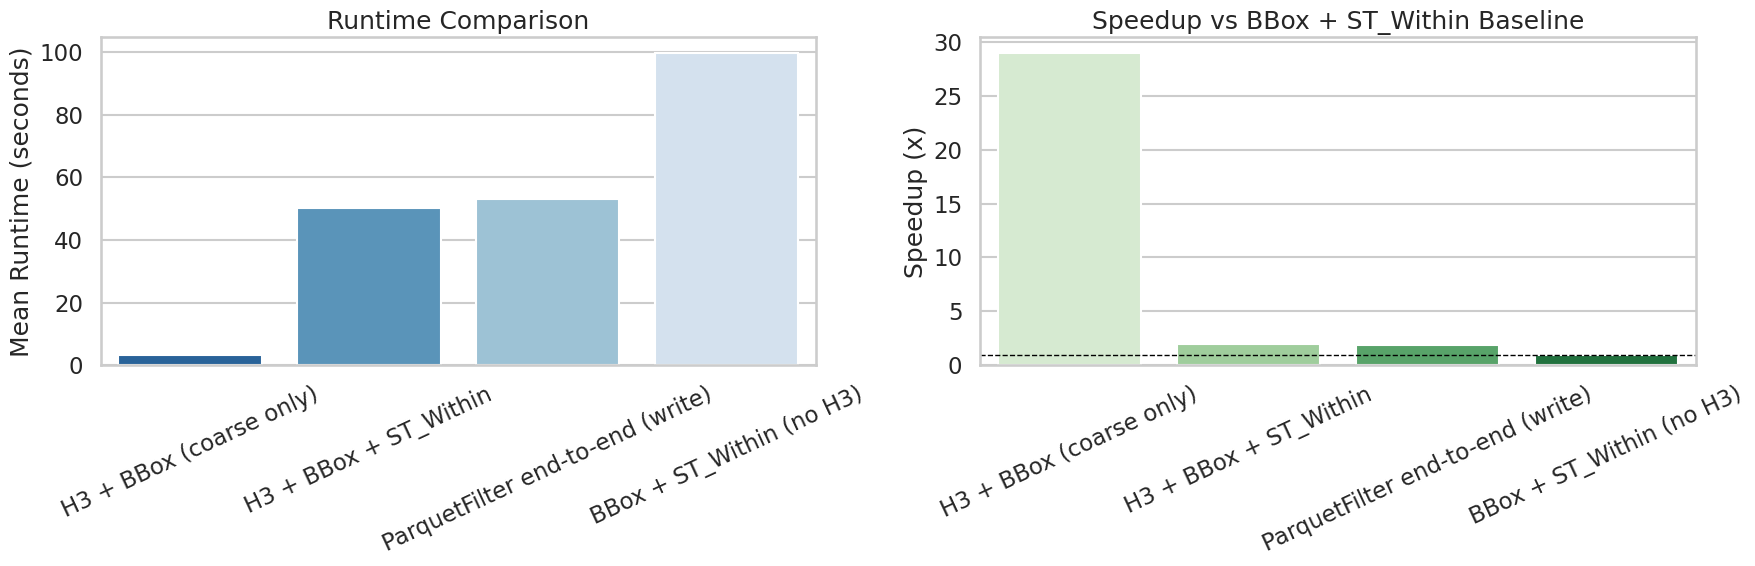

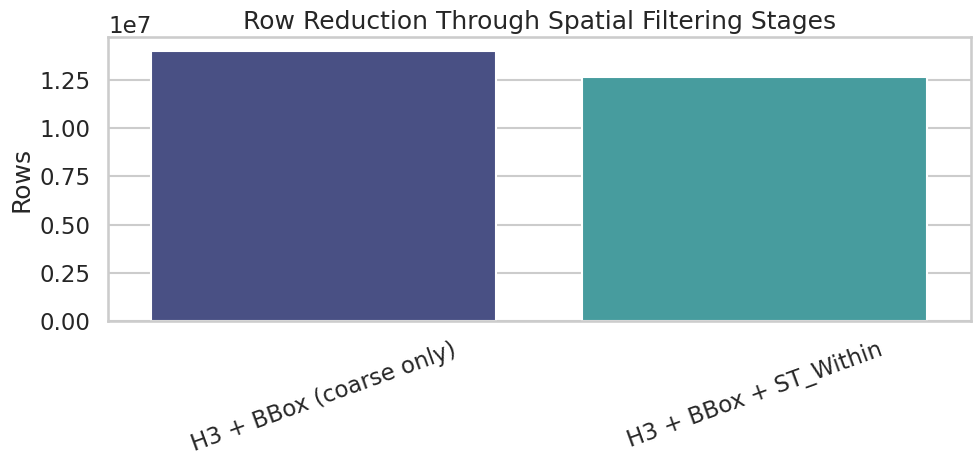


Presentation talking points:
- Fastest scenario: H3 + BBox (coarse only) (3.44s)
- H3 cell cover size: 57,813 cells at resolution 7
- Use H3 + bounding box as coarse pruning before exact ST_Within for best balance of speed and accuracy.
- Treat ParquetFilter end-to-end metric separately because write cost is part of operations, not pure query compute.


In [10]:
import os
import time
from pathlib import Path

import h3
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import spatio_temporal as st

from cpom.altimetry.datasets.parquet_tools.spatio_temporal import (
    polygon_from_mask,
    reproject,
    to_geometry,
 )

# Presentation theme
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.figsize"] = (14, 6)

con.execute("LOAD spatial; LOAD h3;")

# Inputs
benchmark_path = path if "path" in globals() else "/home/willisc3/luna/CPOM/willisc3/new_archive_test/north/cs2/CryoTEMPO_baseline_D/**/*.parquet"
buffer_m = 10000
h3_res = 7
runs = 3

if "gdf" not in globals() or gdf is None:
    gdf = polygon_from_mask(
        "greenland_icesheet_2km_grid_mask_mouginot2019",
        basin_numbers=["NW"],
        target_crs=3413,
    )

polygon, src_crs = to_geometry(gdf)
polygon_4326 = reproject(polygon.buffer(buffer_m), src_crs=src_crs, dst_crs=4326)
cells = h3.geo_to_cells(polygon_4326.__geo_interface__, res=h3_res)
if not cells:
    raise ValueError("No H3 covering cells were generated.")

cell_list = ", ".join(str(h3.str_to_int(c)) for c in cells)
wkt_poly = polygon.wkt.replace("'", "''")
minx, miny, maxx, maxy = polygon.bounds

queries = {
    "BBox + ST_Within (no H3)": f"""
        SELECT COUNT(*)
        FROM read_parquet('{benchmark_path}', hive_partitioning=true)
        WHERE x BETWEEN {minx} AND {maxx}
          AND y BETWEEN {miny} AND {maxy}
          AND ST_Within(ST_Point(x, y), ST_GeomFromText('{wkt_poly}'))
    """,
    "H3 + BBox (coarse only)": f"""
        SELECT COUNT(*)
        FROM read_parquet('{benchmark_path}', hive_partitioning=true)
        WHERE h3_cell_id IN ({cell_list})
          AND x BETWEEN {minx} AND {maxx}
          AND y BETWEEN {miny} AND {maxy}
    """,
    "H3 + BBox + ST_Within": f"""
        SELECT COUNT(*)
        FROM read_parquet('{benchmark_path}', hive_partitioning=true)
        WHERE h3_cell_id IN ({cell_list})
          AND x BETWEEN {minx} AND {maxx}
          AND y BETWEEN {miny} AND {maxy}
          AND ST_Within(ST_Point(x, y), ST_GeomFromText('{wkt_poly}'))
    """,
}

def benchmark_count(label: str, sql: str, n_runs: int = 3):
    # Warm-up run for cache effects
    con.execute(sql).fetchone()

    timings = []
    count_val = None
    for _ in range(n_runs):
        t0 = time.perf_counter()
        count_val = con.execute(sql).fetchone()[0]
        timings.append(time.perf_counter() - t0)

    return {
        "scenario": label,
        "rows": int(count_val),
        "mean_s": float(sum(timings) / len(timings)),
        "min_s": float(min(timings)),
        "max_s": float(max(timings)),
    }

records = [benchmark_count(name, sql, runs) for name, sql in queries.items()]

# Optional: class end-to-end benchmark (includes write cost)
tmp_out = Path("presentation_class_output.parquet")
if tmp_out.exists():
    tmp_out.unlink()

class_timings = []
class_rows = None
for _ in range(runs):
    if tmp_out.exists():
        tmp_out.unlink()
    t0 = time.perf_counter()
    st.ParquetFilter(
        benchmark_path,
    ).get_polygon(
        gdf,
        h3_col="h3_cell_id",
        h3_res=h3_res,
        h3_buffer=buffer_m,
    ).run(
        con,
        output_path=str(tmp_out),
        load_extensions=False,
        verbose=False,
    )
    class_timings.append(time.perf_counter() - t0)
    class_rows = con.execute(f"SELECT COUNT(*) FROM read_parquet('{tmp_out}')").fetchone()[0]

records.append(
    {
        "scenario": "ParquetFilter end-to-end (write)",
        "rows": int(class_rows),
        "mean_s": float(sum(class_timings) / len(class_timings)),
        "min_s": float(min(class_timings)),
        "max_s": float(max(class_timings)),
    }
)

benchmark_df = pd.DataFrame(records).sort_values("mean_s").reset_index(drop=True)
baseline = benchmark_df.loc[benchmark_df["scenario"] == "BBox + ST_Within (no H3)", "mean_s"].iloc[0]
benchmark_df["speedup_vs_baseline"] = baseline / benchmark_df["mean_s"]

display(benchmark_df.style.format({
    "mean_s": "{:.2f}",
    "min_s": "{:.2f}",
    "max_s": "{:.2f}",
    "speedup_vs_baseline": "{:.2f}x",
}))

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.barplot(
    data=benchmark_df,
    x="scenario",
    y="mean_s",
    hue="scenario",
    palette="Blues_r",
    legend=False,
    ax=axes[0],
)
axes[0].set_title("Runtime Comparison")
axes[0].set_ylabel("Mean Runtime (seconds)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=25)

sns.barplot(
    data=benchmark_df,
    x="scenario",
    y="speedup_vs_baseline",
    hue="scenario",
    palette="Greens",
    legend=False,
    ax=axes[1],
)
axes[1].set_title("Speedup vs BBox + ST_Within Baseline")
axes[1].set_ylabel("Speedup (x)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=25)
axes[1].axhline(1.0, ls="--", c="black", lw=1)

plt.tight_layout()
plt.show()

# Candidate reduction chart for the SQL-only pipeline
pipeline_order = [
    "H3 + BBox (coarse only)",
    "H3 + BBox + ST_Within",
]
pipeline_df = benchmark_df[benchmark_df["scenario"].isin(pipeline_order)].copy()
if len(pipeline_df) == 2:
    plt.figure(figsize=(10, 5))
    sns.barplot(data=pipeline_df, x="scenario", y="rows", hue="scenario", palette="mako", legend=False)
    plt.title("Row Reduction Through Spatial Filtering Stages")
    plt.ylabel("Rows")
    plt.xlabel("")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

print("\nPresentation talking points:")
best = benchmark_df.iloc[0]
print(f"- Fastest scenario: {best['scenario']} ({best['mean_s']:.2f}s)")
print(f"- H3 cell cover size: {len(cells):,} cells at resolution {h3_res}")
print("- Use H3 + bounding box as coarse pruning before exact ST_Within for best balance of speed and accuracy.")
print("- Treat ParquetFilter end-to-end metric separately because write cost is part of operations, not pure query compute.")